In [2]:
%pip install -U pandas numpy scikit-learn matplotlib seaborn openpyxl xlrd datasets transformers accelerate

   ---------------------------------------- 0.0/11.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.6/11.7 MB 9.3 MB/s eta 0:00:02
   -------------- ------------------------- 4.2/11.7 MB 11.0 MB/s eta 0:00:01
   ----------------------- ---------------- 6.8/11.7 MB 11.3 MB/s eta 0:00:01
   ------------------------------- -------- 9.2/11.7 MB 11.2 MB/s eta 0:00:01
   ---------------------------------------  11.5/11.7 MB 11.5 MB/s eta 0:00:01
   ---------------------------------------- 11.7/11.7 MB 10.8 MB/s  0:00:01
  Attempting uninstall: transformers
    Found existing installation: transformers 5.14.1
    Uninstalling transformers-5.14.1:
      Successfully uninstalled transformers-5.14.1
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import random
import numpy as np
import pandas as pd
import torch

import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

c:\Users\rayha\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


In [4]:
import sys

print("Python:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nPyTorch version:")
print(torch.__version__)

Python:
c:\Users\rayha\AppData\Local\Programs\Python\Python311\python.exe

Python version:
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]

PyTorch version:
2.5.1+cu121


In [5]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    
    print("GPU is available!")
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

else:
    device = torch.device("cpu")
    
    print("GPU is NOT available.")
    print("Training will use CPU.")

print("\nUsing device:", device)

GPU is available!
GPU: NVIDIA GeForce RTX 4060
CUDA: 12.1

Using device: cuda


In [6]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [7]:
PROJECT_DIR = r"D:\aiub\Samester 10\final term\IDS\model"

print("Project folder:")
print(PROJECT_DIR)

print("\nFolder exists:")
print(os.path.exists(PROJECT_DIR))

Project folder:
D:\aiub\Samester 10\final term\IDS\model

Folder exists:
True


In [8]:
print("Files in project folder:\n")

for file in os.listdir(PROJECT_DIR):
    print(repr(file))

Files in project folder:

'DS_dataset.csv'
'XLM-RoBERTa.ipynb'
'xlm_roberta_intent_model'


In [9]:
import glob

dataset_files = []

for pattern in [
    "DS_dataset.xls",
    "DS_dataset.xlsx",
    "DS_dataset.csv"
]:
    
    path = os.path.join(
        PROJECT_DIR,
        pattern
    )
    
    if os.path.isfile(path):
        dataset_files.append(path)

print("Dataset files found:\n")

for file in dataset_files:
    print(file)

Dataset files found:

D:\aiub\Samester 10\final term\IDS\model\DS_dataset.csv


In [10]:
if len(dataset_files) == 0:
    raise FileNotFoundError(
        "DS_dataset was not found in the project folder."
    )

DATA_PATH = dataset_files[0]

print("Selected dataset:")
print(DATA_PATH)

Selected dataset:
D:\aiub\Samester 10\final term\IDS\model\DS_dataset.csv


In [11]:
if DATA_PATH.lower().endswith(".csv"):
    
    df = pd.read_csv(
        DATA_PATH
    )

elif DATA_PATH.lower().endswith(".xls"):
    
    df = pd.read_excel(
        DATA_PATH,
        engine="xlrd"
    )

elif DATA_PATH.lower().endswith(".xlsx"):
    
    df = pd.read_excel(
        DATA_PATH,
        engine="openpyxl"
    )

else:
    raise ValueError(
        "Unsupported dataset format."
    )

print("Dataset loaded successfully!")
print("\nShape:", df.shape)

Dataset loaded successfully!

Shape: (3150, 4)


In [12]:
df.head()

,Sentence,Language,Intent,Split
0,"book a table in Montenegro for alissa, corneli...",english,bookrestaurant,train
1,"মন্টিনিগ্রোর অস্টেরিয়াতে অ্যালিসা, কর্নেলিয়া...",bangla,bookrestaurant,train
2,"Montenegro er osteria te alissa, cornelia will...",codemixed,bookrestaurant,train
3,I wanna listen to Electroclash,english,playmusic,train
4,আমি ইলেক্ট্রোক্ল্যাশ শুনতে চাই।,bangla,playmusic,train


In [13]:
print("Columns:")
print(df.columns.tolist())

Columns:
['Sentence', 'Language', 'Intent', 'Split']


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Sentence  3150 non-null   str  
 1   Language  3150 non-null   str  
 2   Intent    3150 non-null   str  
 3   Split     3150 non-null   str  
dtypes: str(4)
memory usage: 411.5 KB


In [15]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

Number of rows: 3150
Number of columns: 4


In [16]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Sentence    0
Language    0
Intent      0
Split       0
dtype: int64


In [17]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

Duplicate rows: 3


In [18]:
df.columns = (
    df.columns
    .astype(str)
    .str.strip()
)

print(df.columns.tolist())

['Sentence', 'Language', 'Intent', 'Split']


In [19]:
required_columns = [
    "Sentence",
    "Language",
    "Intent",
    "Split"
]

missing_columns = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing_columns:
    
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("All required columns are present!")

All required columns are present!


In [20]:
df["Sentence"] = (
    df["Sentence"]
    .astype(str)
    .str.strip()
)

df["Language"] = (
    df["Language"]
    .astype(str)
    .str.strip()
)

df["Intent"] = (
    df["Intent"]
    .astype(str)
    .str.strip()
)

df["Split"] = (
    df["Split"]
    .astype(str)
    .str.strip()
)

print("Text and categorical columns cleaned.")

Text and categorical columns cleaned.


In [21]:
print(
    df["Language"].value_counts()
)

Language
english      1050
bangla       1050
codemixed    1050
Name: count, dtype: int64


In [22]:
print(
    "Number of intents:",
    df["Intent"].nunique()
)

print("\nIntent distribution:")

print(
    df["Intent"].value_counts()
)

Number of intents: 7

Intent distribution:
Intent
getweather              504
playmusic               477
searchcreativework      471
addtoplaylist           444
bookrestaurant          432
ratebook                432
searchscreeningevent    390
Name: count, dtype: int64


In [23]:
print(
    "Split distribution:"
)

print(
    df["Split"].value_counts()
)

print(
    "\nUnique split values:"
)

print(
    df["Split"].unique()
)

Split distribution:
Split
train         1908
validation     642
test           600
Name: count, dtype: int64

Unique split values:
<ArrowStringArray>
['train', 'validation', 'test']
Length: 3, dtype: str


In [25]:
df["Split"] = (
    df["Split"]
    .str.lower()
    .str.strip()
)

split_mapping = {
    "train": "train",
    "training": "train",
    
    "validation": "validation",
    "valid": "validation",
    "val": "validation",
    
    "test": "test",
    "testing": "test"
}

df["Split"] = df["Split"].map(
    split_mapping
)

print(
    df["Split"].value_counts()
)

Split
train         1908
validation     642
test           600
Name: count, dtype: int64


In [26]:
if df["Split"].isna().any():
    
    print("Invalid split values found:")
    
    print(
        df[df["Split"].isna()]
    )

else:
    
    print(
        "All split values are valid."
    )

All split values are valid.


In [27]:
train_df = df[
    df["Split"] == "train"
].copy()

val_df = df[
    df["Split"] == "validation"
].copy()

test_df = df[
    df["Split"] == "test"
].copy()

print(
    "Training:",
    len(train_df)
)

print(
    "Validation:",
    len(val_df)
)

print(
    "Test:",
    len(test_df)
)

print(
    "Total:",
    len(train_df)
    + len(val_df)
    + len(test_df)
)

Training: 1908
Validation: 642
Test: 600
Total: 3150


In [28]:
print("TRAIN")
print(train_df["Language"].value_counts())

print("\nVALIDATION")
print(val_df["Language"].value_counts())

print("\nTEST")
print(test_df["Language"].value_counts())

TRAIN
Language
english      636
bangla       636
codemixed    636
Name: count, dtype: int64

VALIDATION
Language
english      214
bangla       214
codemixed    214
Name: count, dtype: int64

TEST
Language
english      200
bangla       200
codemixed    200
Name: count, dtype: int64


In [29]:
label_encoder = LabelEncoder()

label_encoder.fit(
    df["Intent"]
)

num_labels = len(
    label_encoder.classes_
)

print(
    "Number of intent classes:",
    num_labels
)

Number of intent classes: 7


In [30]:
label_mapping = {}

for i, intent in enumerate(
    label_encoder.classes_
):
    
    label_mapping[i] = intent

print(label_mapping)

{0: 'addtoplaylist', 1: 'bookrestaurant', 2: 'getweather', 3: 'playmusic', 4: 'ratebook', 5: 'searchcreativework', 6: 'searchscreeningevent'}


In [31]:
train_df["label"] = label_encoder.transform(
    train_df["Intent"]
)

val_df["label"] = label_encoder.transform(
    val_df["Intent"]
)

test_df["label"] = label_encoder.transform(
    test_df["Intent"]
)

print(
    train_df[
        ["Sentence", "Intent", "label"]
    ].head()
)

                                            Sentence          Intent  label
0  book a table in Montenegro for alissa, corneli...  bookrestaurant      1
1  মন্টিনিগ্রোর অস্টেরিয়াতে অ্যালিসা, কর্নেলিয়া...  bookrestaurant      1
2  Montenegro er osteria te alissa, cornelia will...  bookrestaurant      1
3                     I wanna listen to Electroclash       playmusic      3
4                    আমি ইলেক্ট্রোক্ল্যাশ শুনতে চাই।       playmusic      3


In [32]:
train_dataset = Dataset.from_pandas(
    train_df[
        ["Sentence", "label"]
    ],
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[
        ["Sentence", "label"]
    ],
    preserve_index=False
)

test_dataset = Dataset.from_pandas(
    test_df[
        ["Sentence", "label"]
    ],
    preserve_index=False
)

print("Datasets created successfully!")

print("\nTrain:")
print(train_dataset)

print("\nValidation:")
print(val_dataset)

print("\nTest:")
print(test_dataset)

Datasets created successfully!

Train:
Dataset({
    features: ['Sentence', 'label'],
    num_rows: 1908
})

Validation:
Dataset({
    features: ['Sentence', 'label'],
    num_rows: 642
})

Test:
Dataset({
    features: ['Sentence', 'label'],
    num_rows: 600
})


In [33]:
MODEL_NAME = "FacebookAI/xlm-roberta-base"

print(
    "Model:",
    MODEL_NAME
)

Model: FacebookAI/xlm-roberta-base


In [34]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

print(
    "Tokenizer loaded successfully!"
)

Tokenizer loaded successfully!


In [35]:
text = "Book a restaurant for tomorrow."

tokens = tokenizer(
    text
)

print(tokens)

{'input_ids': [0, 27432, 10, 17666, 100, 127773, 5, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1]}


In [36]:
text = "আগামীকাল একটি রেস্টুরেন্ট বুক করুন।"

tokens = tokenizer(
    text
)

print(tokens)

{'input_ids': [0, 72229, 79968, 14536, 54996, 31797, 33019, 94310, 6, 177963, 14286, 125, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [37]:
text = "আগামীকাল একটা restaurant book করে দাও।"

tokens = tokenizer(
    text
)

print(tokens)

{'input_ids': [0, 72229, 79968, 71896, 17666, 12877, 5507, 60910, 4876, 125, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [38]:
MAX_LENGTH = 128

print(
    "Maximum sequence length:",
    MAX_LENGTH
)

Maximum sequence length: 128


In [39]:
def tokenize_function(examples):
    
    return tokenizer(
        examples["Sentence"],
        truncation=True,
        max_length=MAX_LENGTH
    )

In [40]:
tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True
)

print(
    tokenized_train
)

Map: 100%|██████████| 1908/1908 [00:00<00:00, 20700.56 examples/s]

Dataset({
    features: ['Sentence', 'label', 'input_ids', 'attention_mask'],
    num_rows: 1908
})


In [41]:
tokenized_val = val_dataset.map(
    tokenize_function,
    batched=True
)

print(
    tokenized_val
)

Map: 100%|██████████| 642/642 [00:00<00:00, 25675.98 examples/s]

Dataset({
    features: ['Sentence', 'label', 'input_ids', 'attention_mask'],
    num_rows: 642
})


In [42]:
tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

print(
    tokenized_test
)

Map: 100%|██████████| 600/600 [00:00<00:00, 49937.14 examples/s]

Dataset({
    features: ['Sentence', 'label', 'input_ids', 'attention_mask'],
    num_rows: 600
})


In [43]:
print(
    tokenized_train[0]
)

{'Sentence': 'book a table in Montenegro for alissa, cornelia williams and katrina at osteria', 'label': 1, 'input_ids': [0, 12877, 10, 23180, 23, 209123, 100, 144, 3031, 4, 126041, 92788, 1221, 81176, 136, 156, 101156, 99, 362, 26206, 2], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [44]:
id2label = {
    i: label
    for i, label in enumerate(
        label_encoder.classes_
    )
}

label2id = {
    label: i
    for i, label in id2label.items()
}

print("id2label:")
print(id2label)

id2label:
{0: 'addtoplaylist', 1: 'bookrestaurant', 2: 'getweather', 3: 'playmusic', 4: 'ratebook', 5: 'searchcreativework', 6: 'searchscreeningevent'}


In [45]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

print(
    "XLM-RoBERTa model loaded successfully!"
)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4235.45it/s]
[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLM-RoBERTa model loaded successfully!


In [46]:
model.to(device)

print(
    "Model device:",
    device
)

Model device: cuda


In [47]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print(
    "Data collator ready!"
)

Data collator ready!


In [48]:
def compute_metrics(eval_prediction):

    logits = eval_prediction.predictions
    labels = eval_prediction.label_ids

    predictions = np.argmax(
        logits,
        axis=-1
    )

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_f1": macro_f1
    }

In [49]:
OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "xlm_roberta_intent_model"
)

LEARNING_RATE = 2e-5

TRAIN_BATCH_SIZE = 8

EVAL_BATCH_SIZE = 8

NUM_EPOCHS = 5

WEIGHT_DECAY = 0.01

print("Training configuration:")
print("Output:", OUTPUT_DIR)
print("Learning rate:", LEARNING_RATE)
print("Train batch:", TRAIN_BATCH_SIZE)
print("Eval batch:", EVAL_BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Weight decay:", WEIGHT_DECAY)

Training configuration:
Output: D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model
Learning rate: 2e-05
Train batch: 8
Eval batch: 8
Epochs: 5
Weight decay: 0.01


In [50]:
training_args = TrainingArguments(

    output_dir=OUTPUT_DIR,

    num_train_epochs=NUM_EPOCHS,

    learning_rate=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY,

    per_device_train_batch_size=TRAIN_BATCH_SIZE,

    per_device_eval_batch_size=EVAL_BATCH_SIZE,

    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="f1",

    greater_is_better=True,

    save_total_limit=2,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=SEED
)

print(
    "Training arguments created!"
)

Training arguments created!


In [51]:
trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_train,

    eval_dataset=tokenized_val,

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

print(
    "Trainer created successfully!"
)

Trainer created successfully!


In [52]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Macro F1
1,0.804265,0.098307,0.970405,0.970543,0.970405,0.970245,0.969908
2,0.080206,0.076055,0.984424,0.984548,0.984424,0.984388,0.983155
3,0.030234,0.071812,0.987539,0.987793,0.987539,0.987535,0.986543
4,0.022534,0.049561,0.992212,0.992572,0.992212,0.992219,0.991980
5,0.011664,0.044792,0.993769,0.994111,0.993769,0.993803,0.993491


Writing model shards: 100%|██████████| 1/1 [00:06<00:00,  6.86s/it]


In [53]:
trainer.save_model(
    OUTPUT_DIR
)

tokenizer.save_pretrained(
    OUTPUT_DIR
)

print(
    "Model saved successfully!"
)

print(
    "Saved to:",
    OUTPUT_DIR
)

Writing model shards: 100%|██████████| 1/1 [00:06<00:00,  6.92s/it]

Model saved successfully!
Saved to: D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model


In [54]:
label_mapping_df = pd.DataFrame({
    "label_id": range(num_labels),
    "intent": label_encoder.classes_
})

label_mapping_path = os.path.join(
    OUTPUT_DIR,
    "label_mapping.csv"
)

label_mapping_df.to_csv(
    label_mapping_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    label_mapping_df
)

print(
    "\nSaved:",
    label_mapping_path
)

   label_id                intent
0         0         addtoplaylist
1         1        bookrestaurant
2         2            getweather
3         3             playmusic
4         4              ratebook
5         5    searchcreativework
6         6  searchscreeningevent

Saved: D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model\label_mapping.csv


In [55]:
validation_results = trainer.evaluate(
    tokenized_val
)

print(
    validation_results
)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Macro F1
0.011664,0.044792,5,0.993769,0.994111,0.993769,0.993803,0.993491


{'eval_loss': 0.0447922945022583, 'eval_accuracy': 0.9937694704049844, 'eval_precision': 0.9941108692869031, 'eval_recall': 0.9937694704049844, 'eval_f1': 0.9938030458247248, 'eval_macro_f1': 0.9934913830810953}


In [56]:
test_results = trainer.predict(
    tokenized_test
)

print(
    "Test prediction completed!"
)

Test prediction completed!


In [57]:
test_predictions = np.argmax(
    test_results.predictions,
    axis=-1
)

test_labels = (
    test_results.label_ids
)

print(
    "Predictions:",
    test_predictions[:20]
)

print(
    "\nActual:",
    test_labels[:20]
)

Predictions: [3 3 3 2 2 2 2 2 2 5 5 5 0 0 0 4 4 4 1 1]

Actual: [3 3 3 2 2 2 2 2 2 5 5 5 0 0 0 4 4 4 1 1]


In [58]:
test_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

test_precision, test_recall, test_f1, _ = (
    precision_recall_fscore_support(
        test_labels,
        test_predictions,
        average="weighted",
        zero_division=0
    )
)

test_macro_precision, test_macro_recall, test_macro_f1, _ = (
    precision_recall_fscore_support(
        test_labels,
        test_predictions,
        average="macro",
        zero_division=0
    )
)

print("=" * 60)
print("FINAL XLM-RoBERTa TEST PERFORMANCE")
print("=" * 60)

print(
    f"Accuracy          : {test_accuracy:.4f}"
)

print(
    f"Weighted Precision : {test_precision:.4f}"
)

print(
    f"Weighted Recall    : {test_recall:.4f}"
)

print(
    f"Weighted F1        : {test_f1:.4f}"
)

print(
    f"Macro Precision    : {test_macro_precision:.4f}"
)

print(
    f"Macro Recall       : {test_macro_recall:.4f}"
)

print(
    f"Macro F1           : {test_macro_f1:.4f}"
)

FINAL XLM-RoBERTa TEST PERFORMANCE
Accuracy          : 0.9883
Weighted Precision : 0.9888
Weighted Recall    : 0.9883
Weighted F1        : 0.9884
Macro Precision    : 0.9885
Macro Recall       : 0.9885
Macro F1           : 0.9883


In [59]:
report = classification_report(

    test_labels,

    test_predictions,

    target_names=label_encoder.classes_,

    digits=4,

    zero_division=0
)

print(report)

                      precision    recall  f1-score   support

       addtoplaylist     1.0000    0.9570    0.9780        93
      bookrestaurant     1.0000    1.0000    1.0000        99
          getweather     1.0000    1.0000    1.0000        90
           playmusic     0.9457    1.0000    0.9721        87
            ratebook     1.0000    1.0000    1.0000        75
  searchcreativework     0.9888    0.9778    0.9832        90
searchscreeningevent     0.9848    0.9848    0.9848        66

            accuracy                         0.9883       600
           macro avg     0.9885    0.9885    0.9883       600
        weighted avg     0.9888    0.9883    0.9884       600



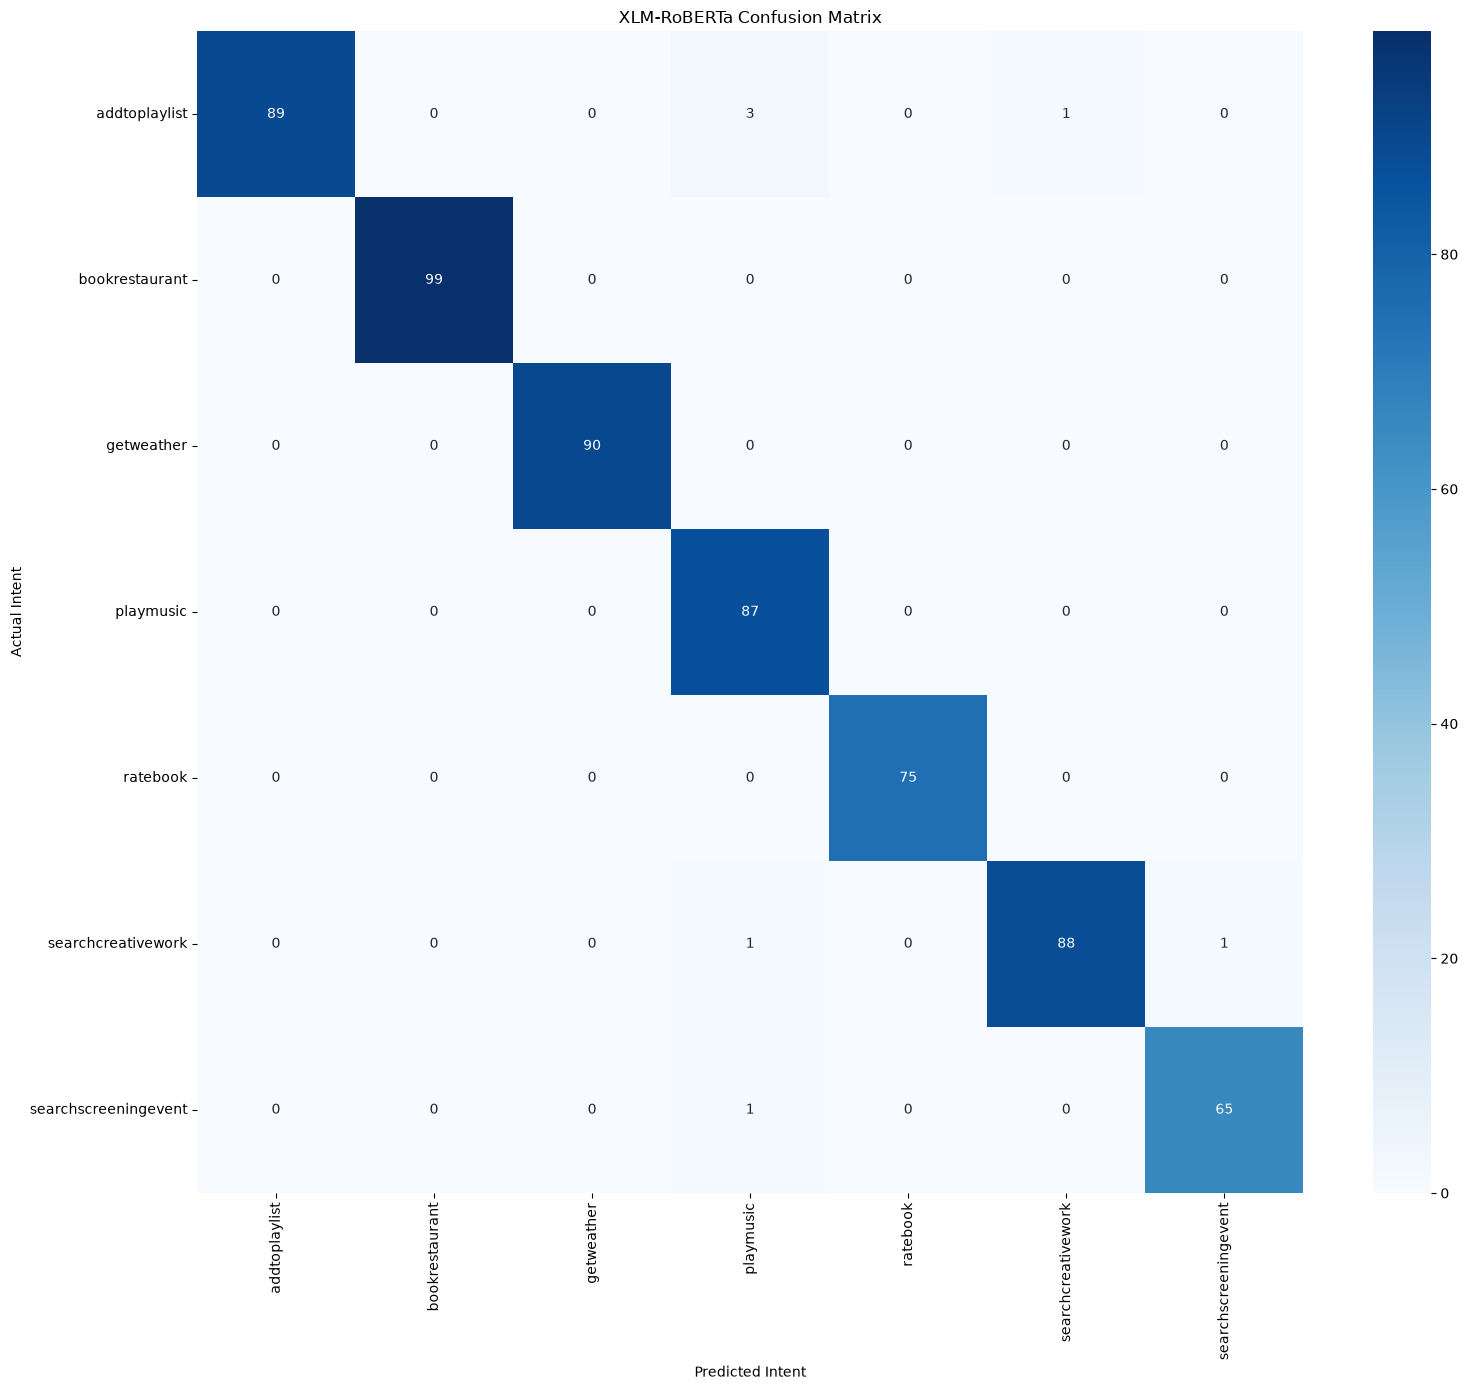

In [60]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(
    figsize=(16, 14)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel(
    "Predicted Intent"
)

plt.ylabel(
    "Actual Intent"
)

plt.title(
    "XLM-RoBERTa Confusion Matrix"
)

plt.xticks(
    rotation=90
)

plt.yticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [61]:
test_output = test_df.copy()

test_output["predicted_intent"] = [
    label_encoder.inverse_transform(
        [prediction]
    )[0]
    for prediction in test_predictions
]

test_output["correct"] = (
    test_output["Intent"]
    ==
    test_output["predicted_intent"]
)

predictions_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

test_output.to_csv(
    predictions_path,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Saved:",
    predictions_path
)

display(
    test_output.head(20)
)

Saved: D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model\test_predictions.csv


,Sentence,Language,Intent,Split,label,predicted_intent,correct
30,I want to hear from Pepe Marchena song Delaware,english,playmusic,test,3,playmusic,True
31,আমি পেপে মারচেনার ডেলাওয়্যার গানটি শুনতে চাই।,bangla,playmusic,test,3,playmusic,True
32,Ami Pepe Marchena er Delaware song ta shunte c...,codemixed,playmusic,test,3,playmusic,True
33,"Will it hail on July 20, 2027 in Ingalls, Malta",english,getweather,test,2,getweather,True
34,২০২৭ সালের ২০ জুলাই মাল্টার ইঙ্গলসে কি শিলাবৃষ...,bangla,getweather,test,2,getweather,True
35,"July 20, 2027 e Malta er Ingalls e ki hail hobe?",codemixed,getweather,test,2,getweather,True
51,Tell me the weather forecast for Island Mountain,english,getweather,test,2,getweather,True
52,আইল্যান্ড মাউন্টেনের আবহাওয়ার পূর্বাভাস বলো।,bangla,getweather,test,2,getweather,True
53,Island Mountain er weather forecast amake bolo.,codemixed,getweather,test,2,getweather,True
78,Can you search the Daring Youth saga?,english,searchcreativework,test,5,searchcreativework,True


In [62]:
errors = test_output[
    test_output["correct"] == False
].copy()

print(
    "Total test samples:",
    len(test_output)
)

print(
    "Correct:",
    test_output["correct"].sum()
)

print(
    "Incorrect:",
    len(errors)
)

display(
    errors[
        [
            "Sentence",
            "Language",
            "Intent",
            "predicted_intent"
        ]
    ].head(30)
)

Total test samples: 600
Correct: 593
Incorrect: 7


,Sentence,Language,Intent,predicted_intent
629,Walk the River namer kajta chai.,codemixed,searchcreativework,playmusic
749,Any Which Way You Can ki 15 seconds er moddhe ...,codemixed,searchscreeningevent,playmusic
1473,Wish to fins a television show called Whole Again,english,searchcreativework,searchscreeningevent
1749,Open my acoustic concentration playlist and pl...,english,addtoplaylist,playmusic
1750,আমার অ্যাকোস্টিক কনসেনট্রেশন প্লেলিস্টটি খোলো ...,bangla,addtoplaylist,playmusic
1751,Amar acoustic concentration playlist open kore...,codemixed,addtoplaylist,playmusic
2228,please maimi yajima's song ta Operación Bikini...,codemixed,addtoplaylist,searchcreativework


In [63]:
language_results = []

for language in sorted(
    test_output["Language"].unique()
):

    language_data = test_output[
        test_output["Language"] == language
    ]

    y_true = label_encoder.transform(
        language_data["Intent"]
    )

    y_pred = label_encoder.transform(
        language_data["predicted_intent"]
    )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    language_results.append({
        "Language": language,
        "Samples": len(language_data),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

language_results_df = pd.DataFrame(
    language_results
)

display(
    language_results_df
)

,Language,Samples,Accuracy,Precision,Recall,F1
0,bangla,200,0.995,0.995167,0.995,0.995001
1,codemixed,200,0.980,0.981406,0.980,0.980144
2,english,200,0.990,0.990384,0.990,0.990015


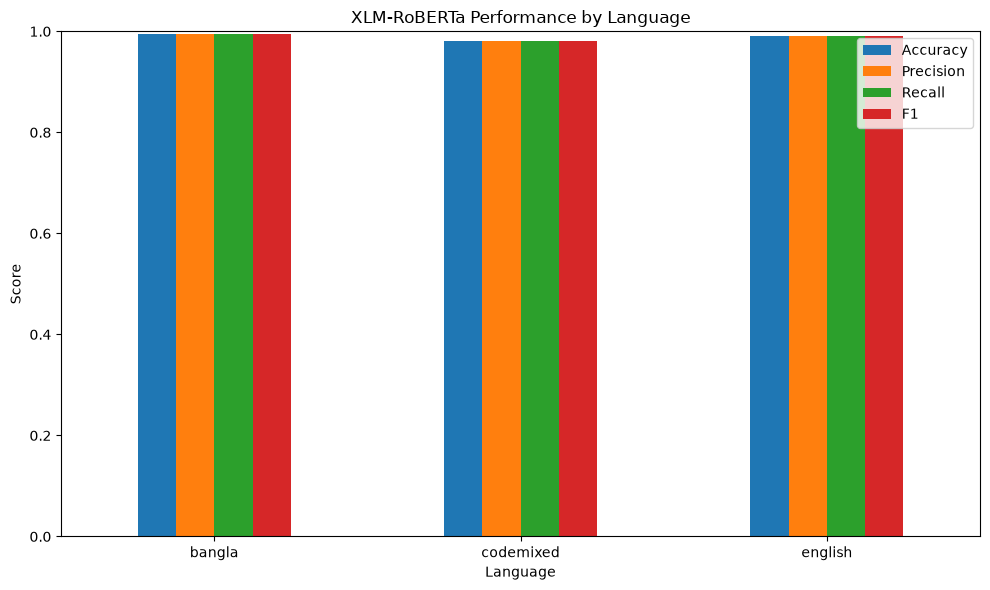

In [64]:
language_results_df.set_index(
    "Language"
)[
    [
        "Accuracy",
        "Precision",
        "Recall",
        "F1"
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "XLM-RoBERTa Performance by Language"
)

plt.xlabel(
    "Language"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [65]:
def predict_intent(sentence):

    model.eval()

    inputs = tokenizer(
        sentence,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model(
            **inputs
        )

    probabilities = torch.softmax(
        outputs.logits,
        dim=-1
    )

    predicted_id = torch.argmax(
        probabilities,
        dim=-1
    ).item()

    confidence = probabilities[
        0,
        predicted_id
    ].item()

    predicted_intent = (
        label_encoder.inverse_transform(
            [predicted_id]
        )[0]
    )

    return predicted_intent, confidence

In [66]:
sentence = "Book a restaurant for me"

intent, confidence = predict_intent(
    sentence
)

print("Sentence:", sentence)
print("Predicted intent:", intent)
print(
    "Confidence:",
    f"{confidence:.4f}"
)

Sentence: Book a restaurant for me
Predicted intent: bookrestaurant
Confidence: 0.9988


In [67]:
sentence = "আমার জন্য একটি রেস্টুরেন্ট বুক করুন"

intent, confidence = predict_intent(
    sentence
)

print("Sentence:", sentence)
print("Predicted intent:", intent)
print(
    "Confidence:",
    f"{confidence:.4f}"
)

Sentence: আমার জন্য একটি রেস্টুরেন্ট বুক করুন
Predicted intent: bookrestaurant
Confidence: 0.9988


In [68]:
sentence = "আমার জন্য একটা restaurant book করে দাও"

intent, confidence = predict_intent(
    sentence
)

print("Sentence:", sentence)
print("Predicted intent:", intent)
print(
    "Confidence:",
    f"{confidence:.4f}"
)

Sentence: আমার জন্য একটা restaurant book করে দাও
Predicted intent: bookrestaurant
Confidence: 0.9988


In [69]:
sentence = "check my account balance"

intent, confidence = predict_intent(
    sentence
)

print("Sentence:", sentence)
print("Predicted intent:", intent)
print(
    "Confidence:",
    f"{confidence:.4f}"
)

Sentence: check my account balance
Predicted intent: searchcreativework
Confidence: 0.9394


In [70]:
sentence = "আমার জন্য balance check করে দাও"

intent, confidence = predict_intent(
    sentence
)

print("Sentence:", sentence)
print("Predicted intent:", intent)
print(
    "Confidence:",
    f"{confidence:.4f}"
)

Sentence: আমার জন্য balance check করে দাও
Predicted intent: searchcreativework
Confidence: 0.9391


In [71]:
sentence = "আমার জন্য weather check করে দাও"

intent, confidence = predict_intent(
    sentence
)

print("Sentence:", sentence)
print("Predicted intent:", intent)
print(
    "Confidence:",
    f"{confidence:.4f}"
)

Sentence: আমার জন্য weather check করে দাও
Predicted intent: getweather
Confidence: 0.9991


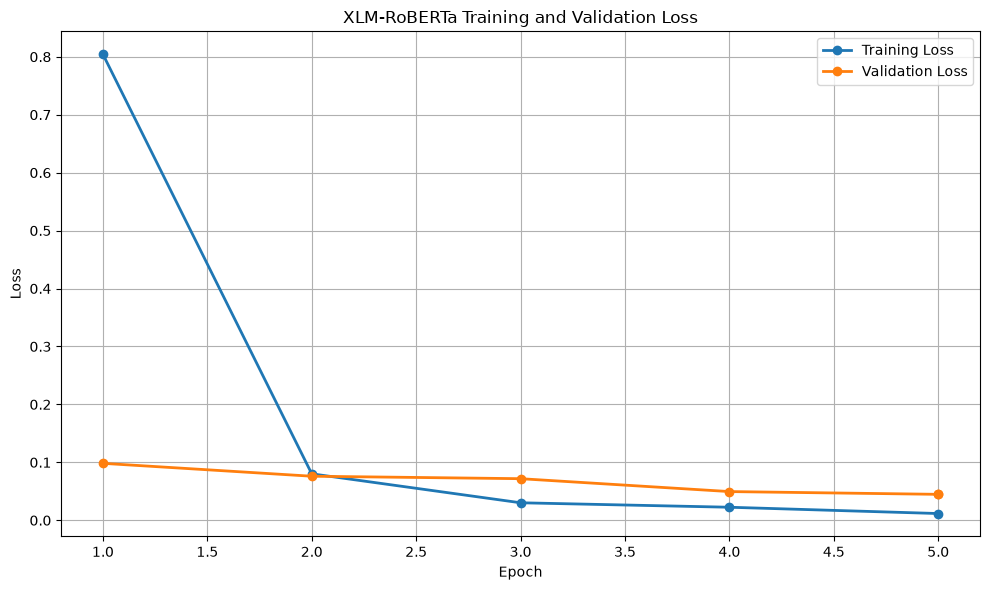

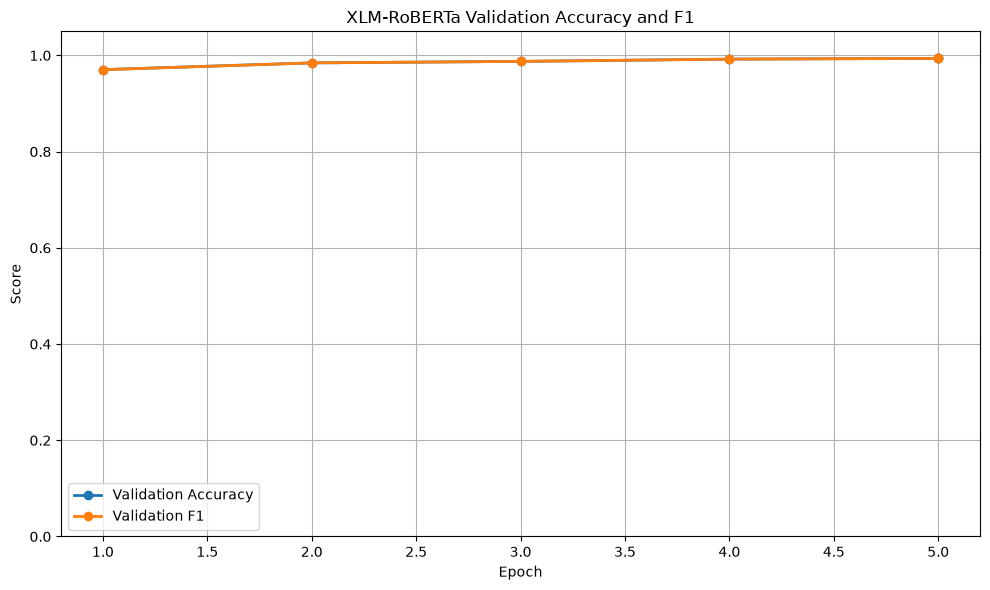

In [72]:
import matplotlib.pyplot as plt

history = trainer.state.log_history

# -----------------------------
# Extract training/validation loss
# -----------------------------
train_epochs = []
train_losses = []

eval_epochs = []
eval_losses = []

eval_f1 = []
eval_accuracy = []

for record in history:

    if "loss" in record and "eval_loss" not in record:
        train_epochs.append(record["epoch"])
        train_losses.append(record["loss"])

    if "eval_loss" in record:
        eval_epochs.append(record["epoch"])
        eval_losses.append(record["eval_loss"])

        if "eval_f1" in record:
            eval_f1.append(record["eval_f1"])

        if "eval_accuracy" in record:
            eval_accuracy.append(record["eval_accuracy"])


# =====================================================
# 1. TRAINING & VALIDATION LOSS
# =====================================================

plt.figure(figsize=(10, 6))

plt.plot(
    train_epochs,
    train_losses,
    marker="o",
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    eval_epochs,
    eval_losses,
    marker="o",
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("XLM-RoBERTa Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# =====================================================
# 2. VALIDATION ACCURACY & F1
# =====================================================

plt.figure(figsize=(10, 6))

plt.plot(
    eval_epochs,
    eval_accuracy,
    marker="o",
    linewidth=2,
    label="Validation Accuracy"
)

plt.plot(
    eval_epochs,
    eval_f1,
    marker="o",
    linewidth=2,
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("XLM-RoBERTa Validation Accuracy and F1")

plt.ylim(0, 1.05)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

DATASET SUMMARY
Total samples       : 3150
Training samples    : 1908
Validation samples  : 642
Test samples        : 600
Number of intents   : 7
Number of languages : 3

Language Distribution:
Language
english      1050
bangla       1050
codemixed    1050
Name: count, dtype: int64

Intent Distribution:
Intent
getweather              504
playmusic               477
searchcreativework      471
addtoplaylist           444
bookrestaurant          432
ratebook                432
searchscreeningevent    390
Name: count, dtype: int64

Dataset Split:
Split
train         1908
validation     642
test           600
Name: count, dtype: int64



OVERALL TEST PERFORMANCE
Accuracy           : 0.9883
Weighted Precision : 0.9888
Weighted Recall    : 0.9883
Weighted F1        : 0.9884

Macro Precision    : 0.9885
Macro Recall       : 0.9885
Macro F1           : 0.9883

CLASS-WISE METRICS


,precision,recall,f1-score,support
addtoplaylist,1.000000,0.956989,0.978022,93.0
bookrestaurant,1.000000,1.000000,1.000000,99.0
getweather,1.000000,1.000000,1.000000,90.0
playmusic,0.945652,1.000000,0.972067,87.0
ratebook,1.000000,1.000000,1.000000,75.0
searchcreativework,0.988764,0.977778,0.983240,90.0
searchscreeningevent,0.984848,0.984848,0.984848,66.0
macro avg,0.988466,0.988517,0.988311,600.0
weighted avg,0.988768,0.988333,0.988362,600.0



Class-wise metrics saved to:
D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model\classwise_metrics.csv


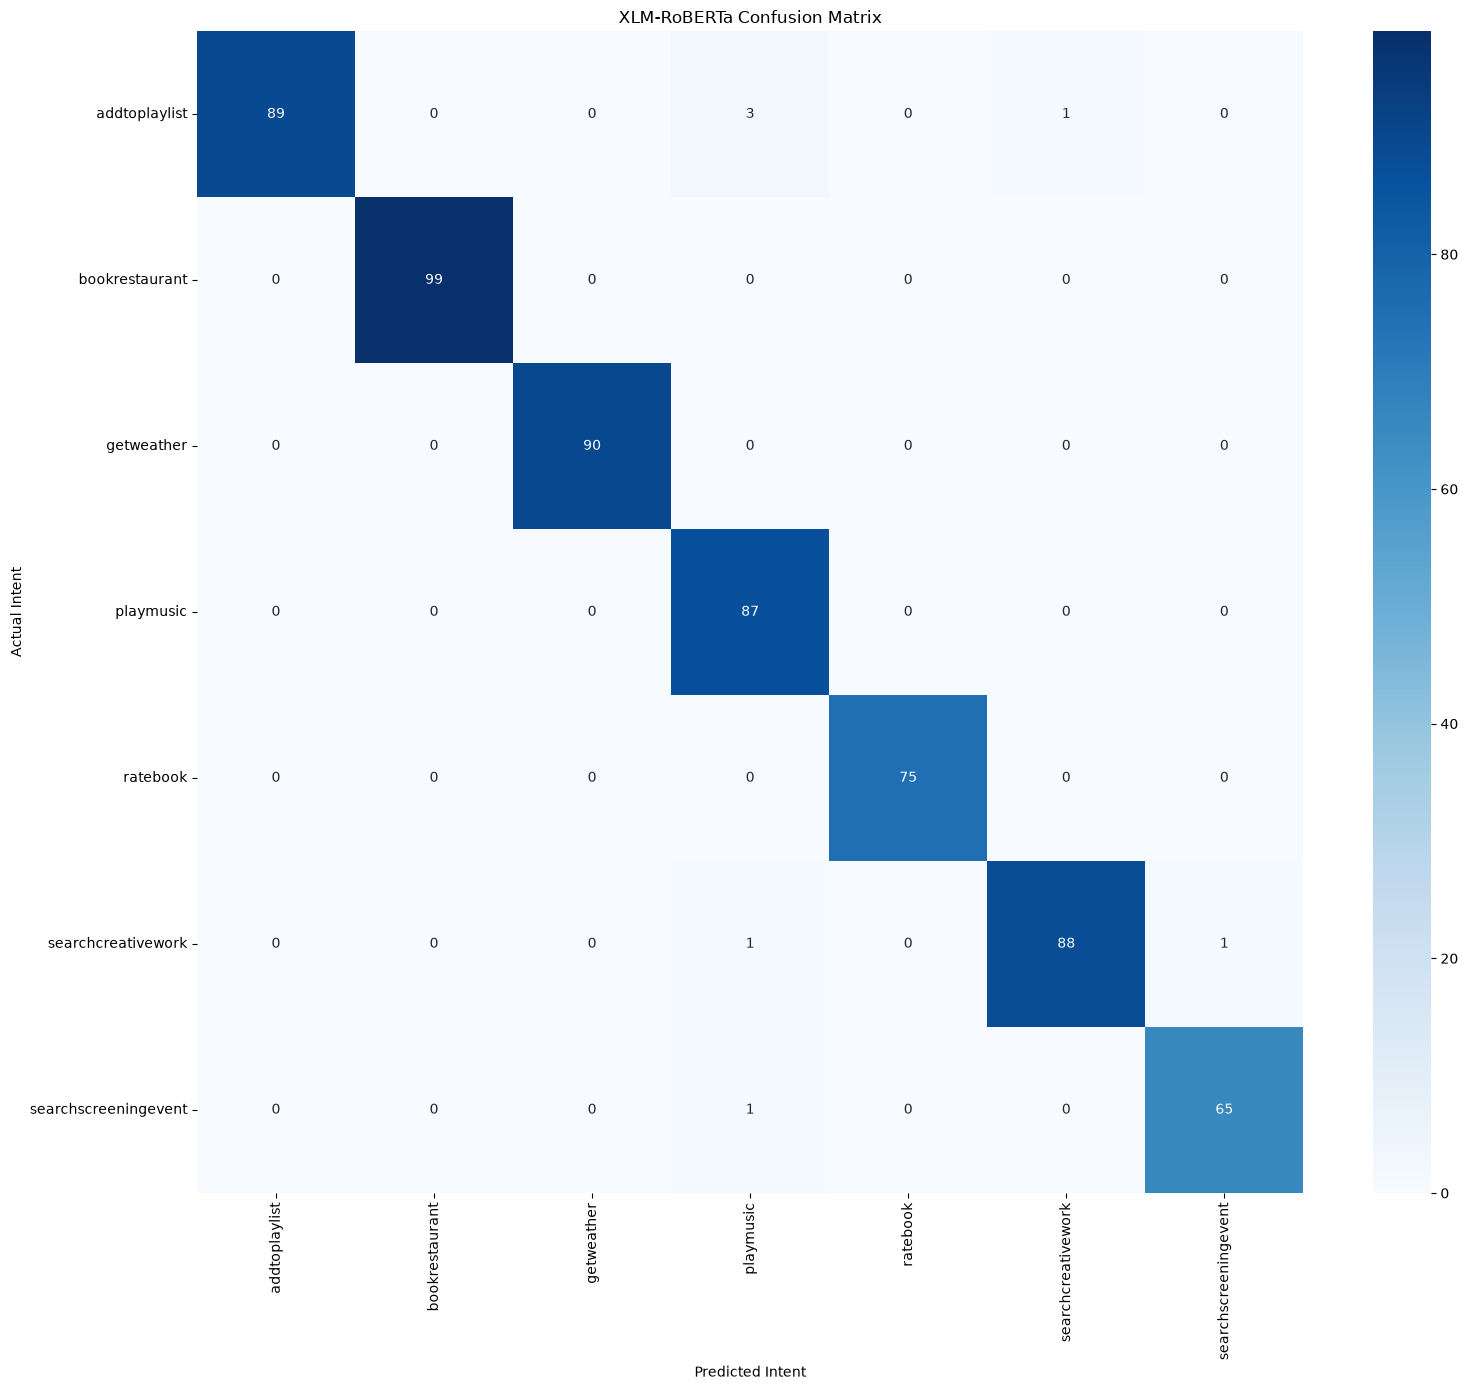

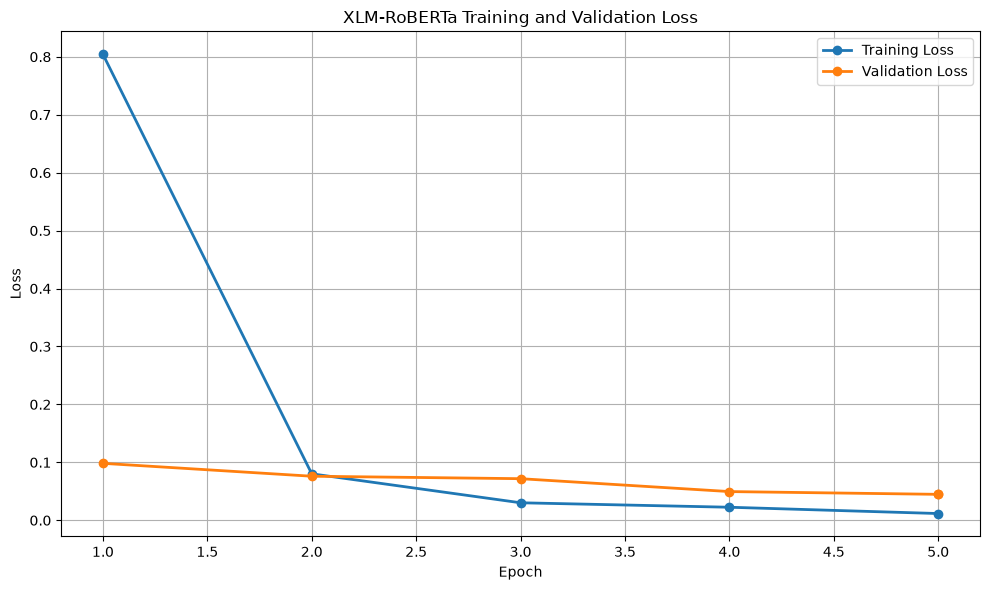

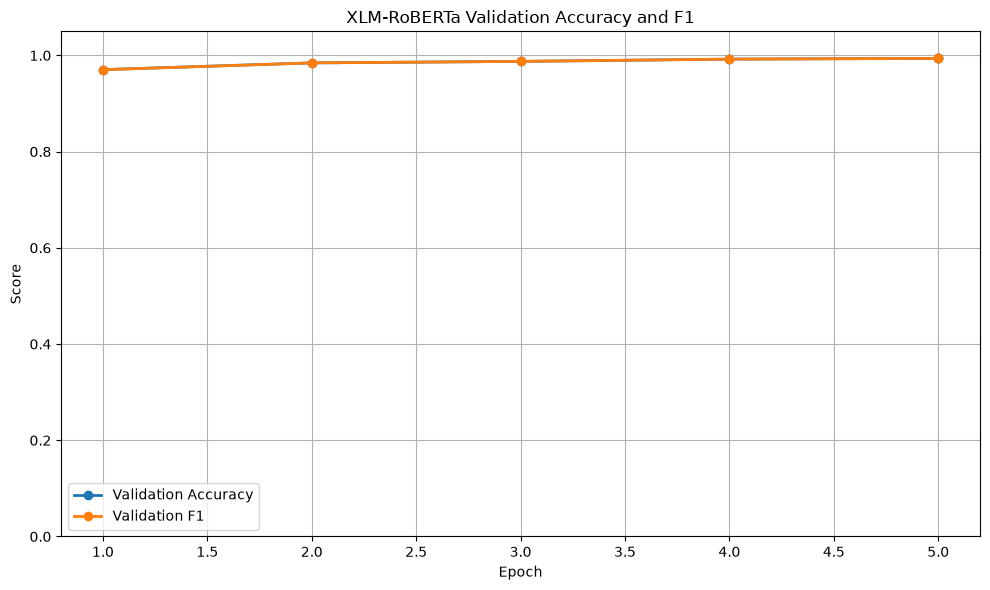


LANGUAGE-WISE PERFORMANCE


,Language,Samples,Accuracy,Precision,Recall,F1
0,bangla,200,0.995,0.995167,0.995,0.995001
1,codemixed,200,0.980,0.981406,0.980,0.980144
2,english,200,0.990,0.990384,0.990,0.990015



ERROR ANALYSIS
Total test samples : 600
Correct predictions: 593
Incorrect predictions: 7

Sample errors:


,Sentence,Language,Intent,predicted_intent
629,Walk the River namer kajta chai.,codemixed,searchcreativework,playmusic
749,Any Which Way You Can ki 15 seconds er moddhe ...,codemixed,searchscreeningevent,playmusic
1473,Wish to fins a television show called Whole Again,english,searchcreativework,searchscreeningevent
1749,Open my acoustic concentration playlist and pl...,english,addtoplaylist,playmusic
1750,আমার অ্যাকোস্টিক কনসেনট্রেশন প্লেলিস্টটি খোলো ...,bangla,addtoplaylist,playmusic
1751,Amar acoustic concentration playlist open kore...,codemixed,addtoplaylist,playmusic
2228,please maimi yajima's song ta Operación Bikini...,codemixed,addtoplaylist,searchcreativework



FINAL ANALYSIS COMPLETE
Model              : FacebookAI/xlm-roberta-base
Dataset size       : 3150
Number of intents  : 7
Test samples       : 600
Test Accuracy      : 0.9883
Test Weighted F1   : 0.9884
Test Macro F1      : 0.9883

Saved files:
1. D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model\classwise_metrics.csv
2. D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model\test_predictions.csv
3. D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model\language_wise_metrics.csv
4. D:\aiub\Samester 10\final term\IDS\model\xlm_roberta_intent_model\overall_metrics.csv


In [73]:
# ============================================================
# FINAL MODEL ANALYSIS
# XLM-RoBERTa
# Dataset Summary + Metrics + Curves + Confusion Matrix
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# ============================================================
# 1. DATASET SUMMARY
# ============================================================

print("=" * 70)
print("DATASET SUMMARY")
print("=" * 70)

print(f"Total samples       : {len(df)}")
print(f"Training samples    : {len(train_df)}")
print(f"Validation samples  : {len(val_df)}")
print(f"Test samples        : {len(test_df)}")
print(f"Number of intents   : {df['Intent'].nunique()}")
print(f"Number of languages : {df['Language'].nunique()}")

print("\nLanguage Distribution:")
print(df["Language"].value_counts())

print("\nIntent Distribution:")
print(df["Intent"].value_counts())

print("\nDataset Split:")
print(df["Split"].value_counts())


# ============================================================
# 2. TEST PREDICTIONS
# ============================================================

# Get predictions from the trained model
test_result = trainer.predict(tokenized_test)

test_predictions = np.argmax(
    test_result.predictions,
    axis=-1
)

test_labels = test_result.label_ids


# ============================================================
# 3. OVERALL PERFORMANCE
# ============================================================

accuracy = accuracy_score(
    test_labels,
    test_predictions
)

precision, recall, f1, _ = (
    precision_recall_fscore_support(
        test_labels,
        test_predictions,
        average="weighted",
        zero_division=0
    )
)

macro_precision, macro_recall, macro_f1, _ = (
    precision_recall_fscore_support(
        test_labels,
        test_predictions,
        average="macro",
        zero_division=0
    )
)

print("\n" + "=" * 70)
print("OVERALL TEST PERFORMANCE")
print("=" * 70)

print(f"Accuracy           : {accuracy:.4f}")
print(f"Weighted Precision : {precision:.4f}")
print(f"Weighted Recall    : {recall:.4f}")
print(f"Weighted F1        : {f1:.4f}")

print(f"\nMacro Precision    : {macro_precision:.4f}")
print(f"Macro Recall       : {macro_recall:.4f}")
print(f"Macro F1           : {macro_f1:.4f}")


# ============================================================
# 4. CLASS-WISE METRICS
# ============================================================

class_report = classification_report(
    test_labels,
    test_predictions,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

classwise_metrics = pd.DataFrame(
    class_report
).transpose()

# Remove overall accuracy row
classwise_metrics = classwise_metrics.drop(
    ["accuracy"],
    errors="ignore"
)

# Keep useful columns
classwise_metrics = classwise_metrics[
    ["precision", "recall", "f1-score", "support"]
]

print("\n" + "=" * 70)
print("CLASS-WISE METRICS")
print("=" * 70)

display(classwise_metrics)


# ============================================================
# 5. SAVE CLASS-WISE METRICS
# ============================================================

classwise_path = os.path.join(
    OUTPUT_DIR,
    "classwise_metrics.csv"
)

classwise_metrics.to_csv(
    classwise_path,
    encoding="utf-8-sig"
)

print("\nClass-wise metrics saved to:")
print(classwise_path)


# ============================================================
# 6. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels,
    test_predictions
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Intent")
plt.ylabel("Actual Intent")

plt.title(
    "XLM-RoBERTa Confusion Matrix"
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 7. TRAINING & VALIDATION LOSS CURVE
# ============================================================

history = trainer.state.log_history

train_epochs = []
train_losses = []

eval_epochs = []
eval_losses = []

eval_accuracy = []
eval_f1 = []

for record in history:

    # Training loss
    if (
        "loss" in record
        and "eval_loss" not in record
    ):
        train_epochs.append(
            record.get("epoch")
        )

        train_losses.append(
            record["loss"]
        )

    # Validation metrics
    if "eval_loss" in record:

        eval_epochs.append(
            record.get("epoch")
        )

        eval_losses.append(
            record["eval_loss"]
        )

        if "eval_accuracy" in record:
            eval_accuracy.append(
                record["eval_accuracy"]
            )

        if "eval_f1" in record:
            eval_f1.append(
                record["eval_f1"]
            )


# Remove None values if present
train_data = [
    (e, l)
    for e, l in zip(
        train_epochs,
        train_losses
    )
    if e is not None
]

eval_data = [
    (e, l)
    for e, l in zip(
        eval_epochs,
        eval_losses
    )
    if e is not None
]

if train_data:
    train_epochs, train_losses = zip(
        *train_data
    )

if eval_data:
    eval_epochs, eval_losses = zip(
        *eval_data
    )


plt.figure(figsize=(10, 6))

if train_data:
    plt.plot(
        train_epochs,
        train_losses,
        marker="o",
        linewidth=2,
        label="Training Loss"
    )

if eval_data:
    plt.plot(
        eval_epochs,
        eval_losses,
        marker="o",
        linewidth=2,
        label="Validation Loss"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "XLM-RoBERTa Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 8. VALIDATION ACCURACY & F1 CURVE
# ============================================================

if len(eval_accuracy) > 0:

    plt.figure(figsize=(10, 6))

    plt.plot(
        eval_epochs,
        eval_accuracy,
        marker="o",
        linewidth=2,
        label="Validation Accuracy"
    )

    if len(eval_f1) > 0:

        plt.plot(
            eval_epochs,
            eval_f1,
            marker="o",
            linewidth=2,
            label="Validation F1"
        )

    plt.xlabel("Epoch")
    plt.ylabel("Score")

    plt.title(
        "XLM-RoBERTa Validation Accuracy and F1"
    )

    plt.ylim(0, 1.05)

    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


# ============================================================
# 9. LANGUAGE-WISE PERFORMANCE
# ============================================================

test_output = test_df.copy()

test_output["predicted_intent"] = [
    label_encoder.inverse_transform(
        [prediction]
    )[0]
    for prediction in test_predictions
]

test_output["correct"] = (
    test_output["Intent"]
    ==
    test_output["predicted_intent"]
)

language_results = []

for language in sorted(
    test_output["Language"].unique()
):

    language_data = test_output[
        test_output["Language"] == language
    ]

    y_true = label_encoder.transform(
        language_data["Intent"]
    )

    y_pred = label_encoder.transform(
        language_data["predicted_intent"]
    )

    lang_accuracy = accuracy_score(
        y_true,
        y_pred
    )

    lang_precision, lang_recall, lang_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )
    )

    language_results.append({
        "Language": language,
        "Samples": len(language_data),
        "Accuracy": lang_accuracy,
        "Precision": lang_precision,
        "Recall": lang_recall,
        "F1": lang_f1
    })

language_results_df = pd.DataFrame(
    language_results
)

print("\n" + "=" * 70)
print("LANGUAGE-WISE PERFORMANCE")
print("=" * 70)

display(language_results_df)


# ============================================================
# 10. ERROR ANALYSIS
# ============================================================

errors = test_output[
    test_output["correct"] == False
].copy()

print("\n" + "=" * 70)
print("ERROR ANALYSIS")
print("=" * 70)

print(
    f"Total test samples : {len(test_output)}"
)

print(
    f"Correct predictions: {test_output['correct'].sum()}"
)

print(
    f"Incorrect predictions: {len(errors)}"
)

print("\nSample errors:")

display(
    errors[
        [
            "Sentence",
            "Language",
            "Intent",
            "predicted_intent"
        ]
    ].head(20)
)


# ============================================================
# 11. SAVE FINAL RESULTS
# ============================================================

# Save predictions
predictions_path = os.path.join(
    OUTPUT_DIR,
    "test_predictions.csv"
)

test_output.to_csv(
    predictions_path,
    index=False,
    encoding="utf-8-sig"
)

# Save language metrics
language_path = os.path.join(
    OUTPUT_DIR,
    "language_wise_metrics.csv"
)

language_results_df.to_csv(
    language_path,
    index=False,
    encoding="utf-8-sig"
)

# Save overall metrics
overall_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        macro_precision,
        macro_recall,
        macro_f1
    ]
})

overall_path = os.path.join(
    OUTPUT_DIR,
    "overall_metrics.csv"
)

overall_metrics.to_csv(
    overall_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 12. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL ANALYSIS COMPLETE")
print("=" * 70)

print(f"Model              : {MODEL_NAME}")
print(f"Dataset size       : {len(df)}")
print(f"Number of intents  : {num_labels}")
print(f"Test samples       : {len(test_df)}")
print(f"Test Accuracy      : {accuracy:.4f}")
print(f"Test Weighted F1   : {f1:.4f}")
print(f"Test Macro F1      : {macro_f1:.4f}")

print("\nSaved files:")

print(
    "1.",
    classwise_path
)

print(
    "2.",
    predictions_path
)

print(
    "3.",
    language_path
)

print(
    "4.",
    overall_path
)